# 1. EDA PART

In [72]:

#load data
from pathlib import Path
import pandas as pd
#this is for numerical calculations
import numpy as np
#create charts and visualizations
import matplotlib.pyplot as plt
#create statistical charts and heatmaps
import seaborn as sns
#for scaling part
from sklearn.preprocessing import StandardScaler

#grid show case
sns.set_theme(style="whitegrid")

#dataset path
project_root = Path("..")
DATA_PATH = project_root / "data" / "raw" / "energy_data_set.csv"

#load the CSV and convert the date column to datetime format
df = pd.read_csv(DATA_PATH, parse_dates=["date"])

#arrange the data in chronological order
df = df.sort_values("date").reset_index(drop=True)

#display first five rows
df.head()


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [49]:
#it shows the number of rows and columns of dataset
print("Dataset shape :", df.shape)

#shows all column names
print("Column names :")
print(df.columns.tolist())

#it shows data types and data counts
print("Dataset information :")
df.info()

#display the first and last timestamps
print("Dataset time range:")
print("Start :", df["date"].min())
print("End :  ", df["date"].max())

#display 
display(df.describe().T)


Dataset shape : (19735, 29)
Column names :
['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2']
Dataset information :
<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         19735 non-null  datetime64[us]
 1   Appliances   19735 non-null  int64         
 2   lights       19735 non-null  int64         
 3   T1           19735 non-null  float64       
 4   RH_1         19735 non-null  float64       
 5   T2           19735 non-null  float64       
 6   RH_2         19735 non-null  float64       
 7   T3           19735 non-null  float64       
 8   RH_3         19735 non-null  float64       
 9   T4           19735 non-null  float64       
 1

,count,mean,min,25%,50%,75%,max,std
date,19735,2016-03-20 05:29:59.999999,2016-01-11 17:00:00,2016-02-14 23:15:00,2016-03-20 05:30:00,2016-04-23 11:45:00,2016-05-27 18:00:00,NaN
Appliances,19735.0,97.694958,10.0,50.0,60.0,100.0,1080.0,102.524891
lights,19735.0,3.801875,0.0,0.0,0.0,0.0,70.0,7.935988
T1,19735.0,21.686571,16.79,20.76,21.6,22.6,26.26,1.606066
RH_1,19735.0,40.259739,27.023333,37.333333,39.656667,43.066667,63.36,3.979299
T2,19735.0,20.341219,16.1,18.79,20.0,21.5,29.856667,2.192974
RH_2,19735.0,40.42042,20.463333,37.9,40.5,43.26,56.026667,4.069813
T3,19735.0,22.267611,17.2,20.79,22.1,23.29,29.236,2.006111
RH_3,19735.0,39.2425,28.766667,36.9,38.53,41.76,50.163333,3.254576
T4,19735.0,20.855335,15.1,19.53,20.666667,22.1,26.2,2.042884


In [50]:

#count missing values
missing_values = df.isnull().sum()
print("Missing values in each column:")
display(missing_values[missing_values > 0])
#calculate the total number of missing values
print("Total missing values:", df.isnull().sum().sum())

#count total duplicated rows
print("Duplicate rows:", df.duplicated().sum())

#check for repeated timestamps
print("Duplicate timestamps:", df["date"].duplicated().sum())

#display the number of missing values as a percentage
missing_percentage = (df.isnull().mean() * 100).round(2)

print("\nMissing value percentage by column: \n" ,missing_percentage)


Missing values in each column:


Series([], dtype: int64)

Total missing values: 0
Duplicate rows: 0
Duplicate timestamps: 0

Missing value percentage by column: 
 date           0.0
Appliances     0.0
lights         0.0
T1             0.0
RH_1           0.0
T2             0.0
RH_2           0.0
T3             0.0
RH_3           0.0
T4             0.0
RH_4           0.0
T5             0.0
RH_5           0.0
T6             0.0
RH_6           0.0
T7             0.0
RH_7           0.0
T8             0.0
RH_8           0.0
T9             0.0
RH_9           0.0
T_out          0.0
Press_mm_hg    0.0
RH_out         0.0
Windspeed      0.0
Visibility     0.0
Tdewpoint      0.0
rv1            0.0
rv2            0.0
dtype: float64


In [51]:
#calculate the time difference between consecutive observations
time_gaps = df["date"].diff()

#it shows how often each time interval occurs
print("Most common time intervals:")
display(time_gaps.value_counts().head(10))

#calculate the expected interval between observations
expected_interval = pd.Timedelta(minutes=10)

#count intervals that differ from the expected 10 minutes
unusual_gaps = time_gaps[
    time_gaps.notna() & (time_gaps != expected_interval)
]
print("\nIntervals different from 10 minutes:", len(unusual_gaps))

#display a few of unusual intervals
print("\nFew of unusual time intervals:")
display(unusual_gaps.head(10))

#calculate the number of unique calendar dates in the dataset
print("\nNumber of unique dates:", df["date"].dt.date.nunique())


Most common time intervals:


date
0 days 00:10:00    19734
Name: count, dtype: int64


Intervals different from 10 minutes: 0

Few of unusual time intervals:


Series([], Name: date, dtype: timedelta64[us])


Number of unique dates: 138


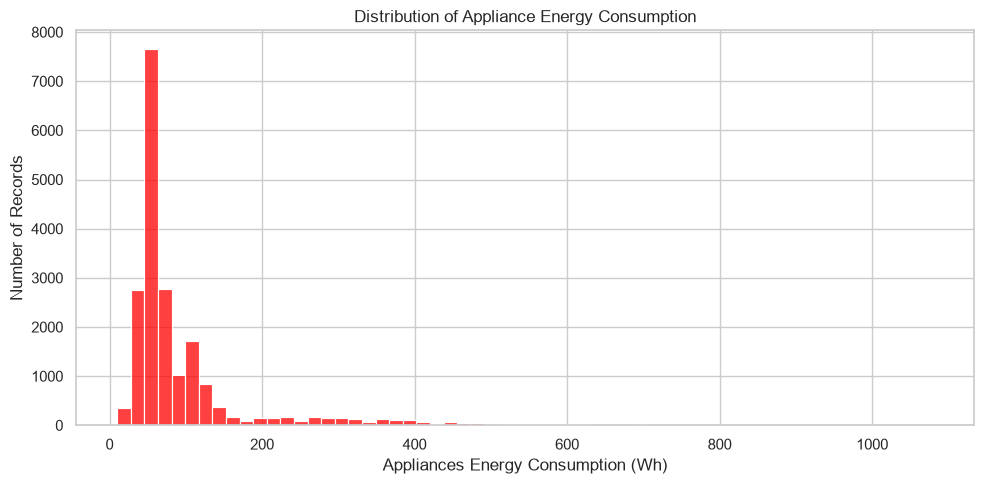

In [52]:
#Target variable distribution (Appliance)


#create two charts side by side
plt.figure(figsize=(10, 5))

#plot a histogram to show how frequently energy values occur
sns.histplot (data=df,x="Appliances",bins=60,color="red")

plt.title("Distribution of Appliance Energy Consumption")
plt.xlabel("Appliances Energy Consumption (Wh)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()


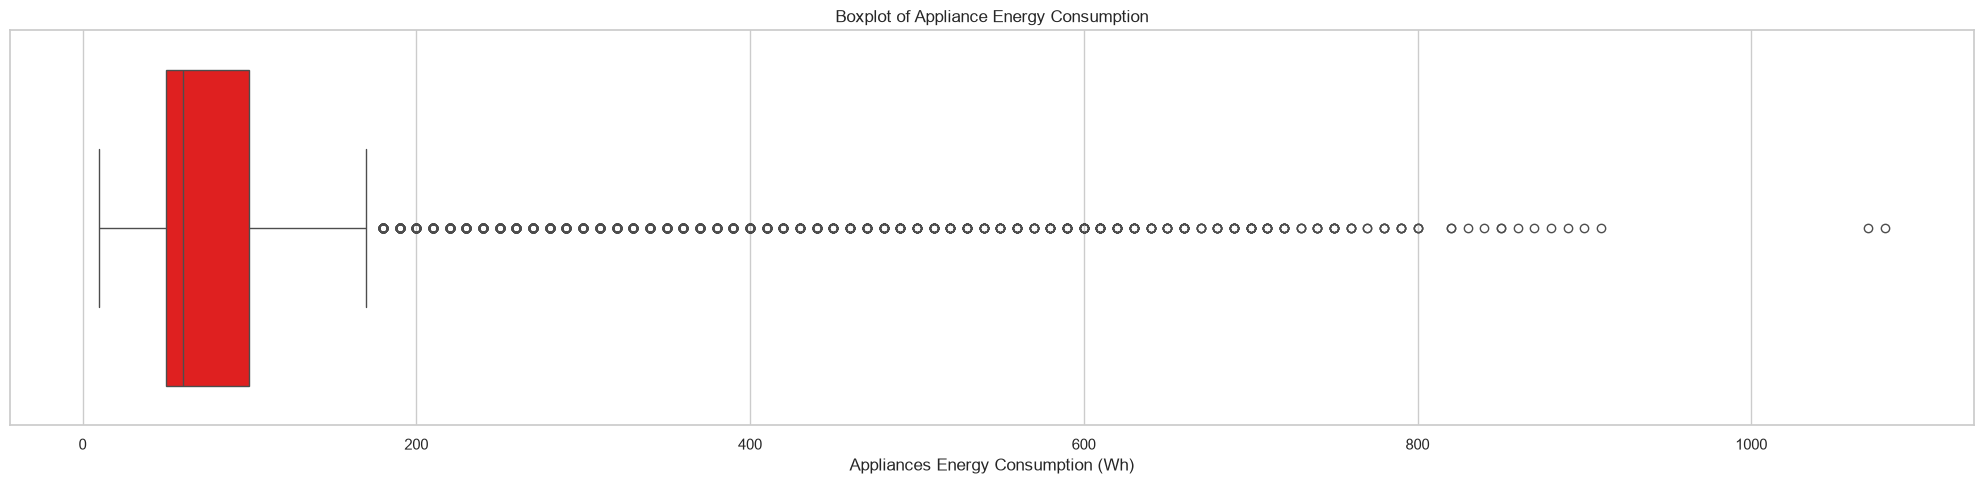

In [53]:
#Box Plot
plt.figure(figsize=(20, 5))

sns.boxplot(
    x=df["Appliances"],
    color="red"
)

plt.title("Boxplot of Appliance Energy Consumption")
plt.xlabel("Appliances Energy Consumption (Wh)")

plt.tight_layout()
plt.show()

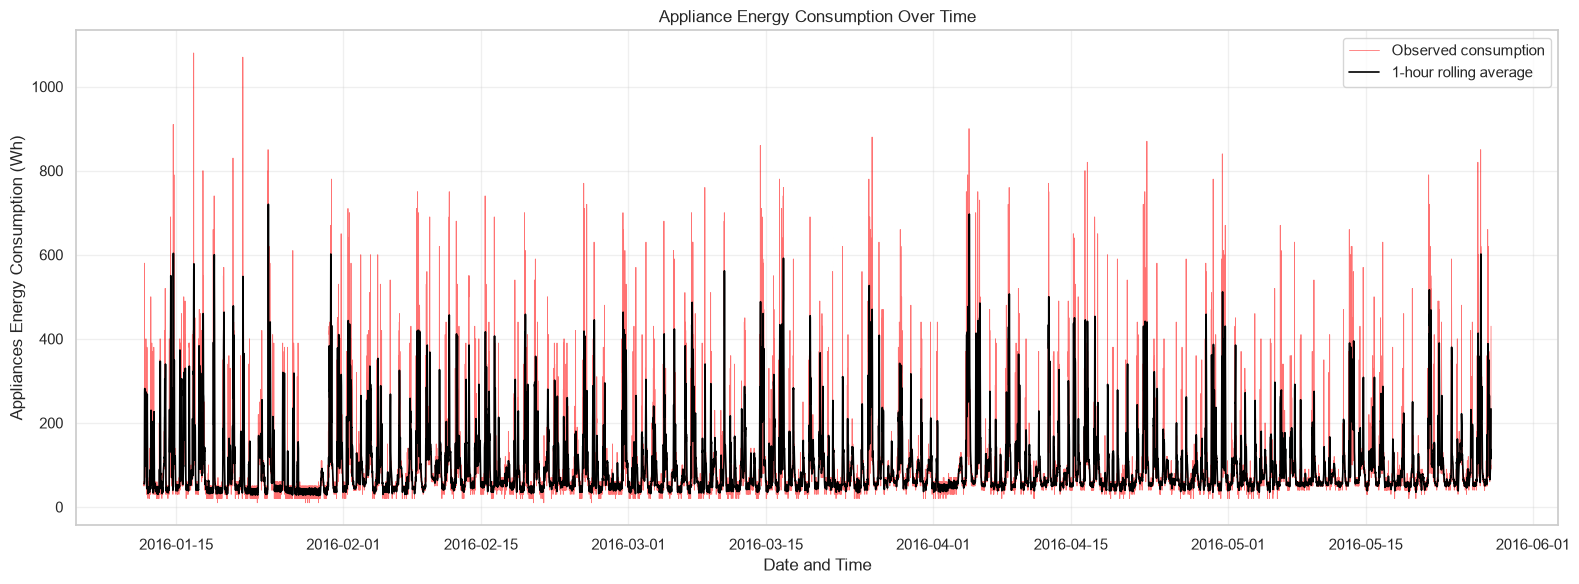

In [54]:
#Energy Consumption Over Time


#create a time series line chart
fig, ax = plt.subplots(figsize=(16, 6))

#original appliance energy measurements
ax.plot (df["date"],df["Appliances"],color="red",linewidth=0.6, alpha=0.55,label="Observed consumption")

#calculate a 1 hour rolling average (6 observations for 10 minutes)
hourly_rolling_mean = (df.set_index("date")["Appliances"].rolling(window=6, min_periods=6).mean())

#average appliance energy 
ax.plot (hourly_rolling_mean.index,hourly_rolling_mean,color="black",linewidth=1.2,label="1-hour rolling average")

# Add chart title and axis labels
ax.set_title("Appliance Energy Consumption Over Time")
ax.set_xlabel("Date and Time")
ax.set_ylabel("Appliances Energy Consumption (Wh)")

# Add legend and grid
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


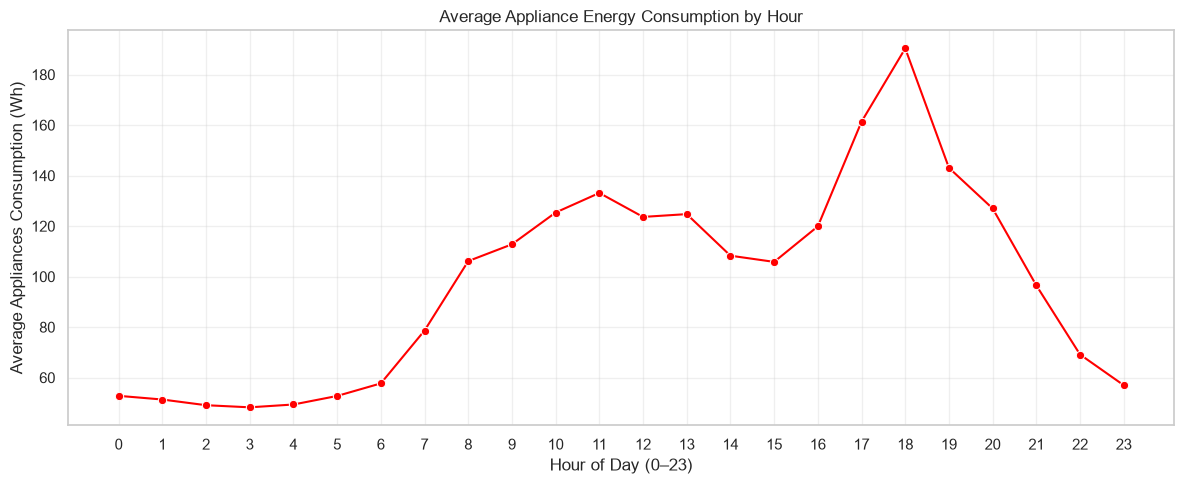

In [55]:
#Average Energy Consumption by Hour

#extract the hour of the day from each timestamp
df["hour"] = df["date"].dt.hour

#calculate average appliance consumption for each hour
hourly_consumption = (df.groupby("hour")["Appliances"].mean())

#plot average consumption by hour
plt.figure(figsize=(12, 5))

sns.lineplot (x=hourly_consumption.index,y=hourly_consumption.values,marker="o",color="red")

plt.title("Average Appliance Energy Consumption by Hour")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Average Appliances Consumption (Wh)")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


/var/folders/8y/kj2ttrds0x9cjtzq28y1qnkm0000gn/T/ipykernel_70388/1977342062.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["date"].dt.dayofweek


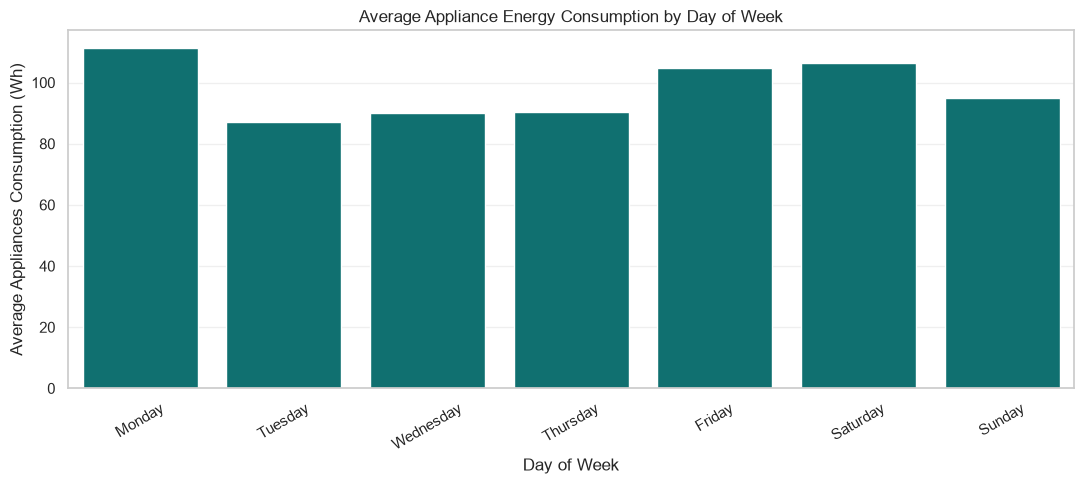

In [56]:

#Average Energy Consumption by Day of the Week

#extract the day of the week from the time stamp
#Monday = 0 and Sunday = 6
df["day_of_week"] = df["date"].dt.dayofweek

#create readable day names
df["day_name"] = df["date"].dt.day_name()

#Define the correct order for weekdays
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday","Friday", "Saturday", "Sunday"]

# Calculate average appliance consumption by day
daily_consumption = ( df.groupby("day_name")["Appliances"].mean().reindex(day_order))

# Plot average consumption by day of the week
plt.figure (figsize=(11, 5))

sns.barplot (x=daily_consumption.index,y=daily_consumption.values,color="teal")

plt.title("Average Appliance Energy Consumption by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Appliances Consumption (Wh)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


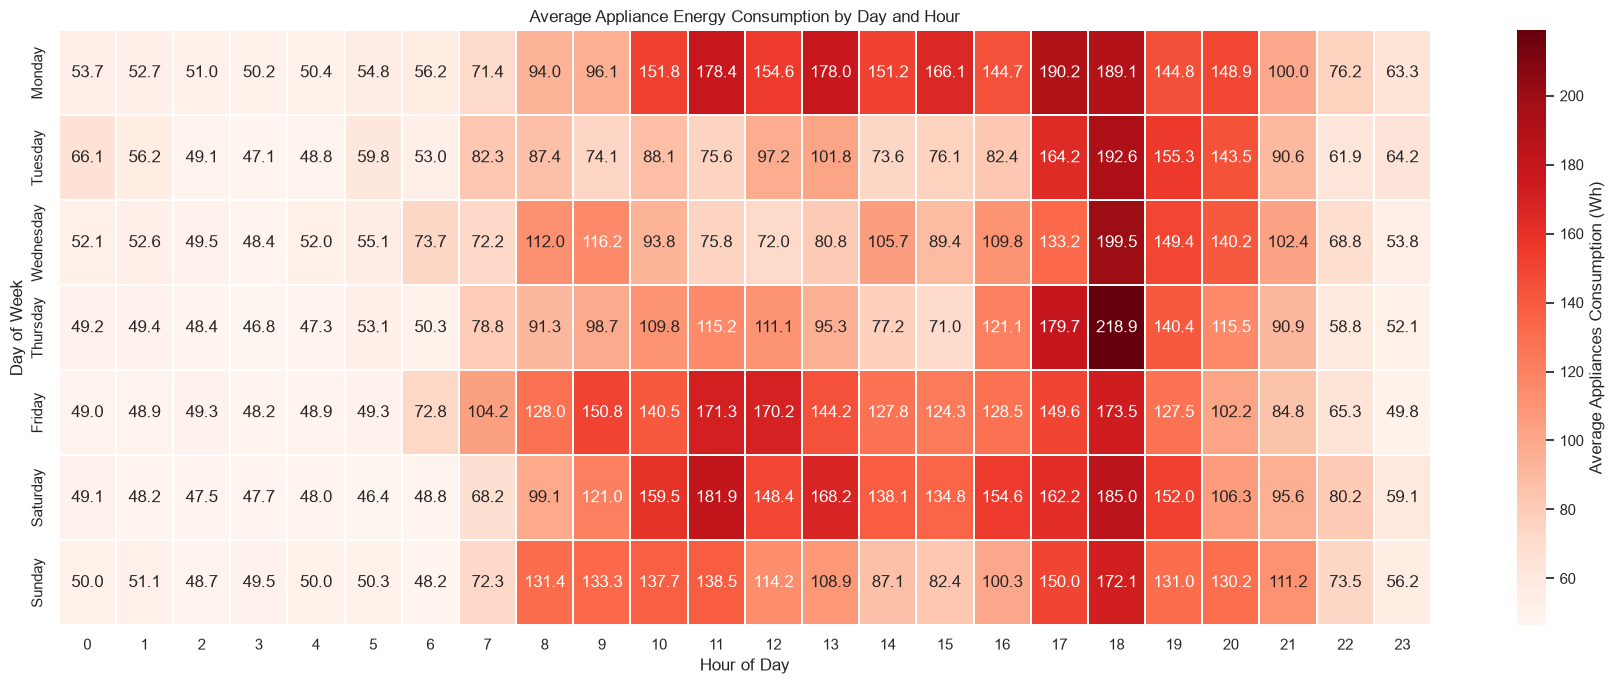

In [57]:
#Heatmap of Average Consumption by Day and Hour


#create a table with days as rows and hours as columns
hour_day_table = df.pivot_table (index="day_name",columns="hour",values="Appliances",aggfunc="mean")

#reorder the days from Monday to Sunday
hour_day_table = hour_day_table.reindex(day_order)

#plot the heatmap
plt.figure(figsize=(18, 7))

sns.heatmap (hour_day_table,cmap="Reds",annot=True,fmt=".1f",linewidths=0.2,cbar_kws={"label": "Average Appliances Consumption (Wh)"})

plt.title("Average Appliance Energy Consumption by Day and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")

plt.tight_layout()
plt.show()

Feature correlations with Appliances:


,Correlation with Appliances
hour,0.216792
lights,0.197278
RH_out,-0.152282
T2,0.120073
T6,0.117638
T_out,0.099155
RH_8,-0.094039
Windspeed,0.087122
RH_1,0.086031
T3,0.085060


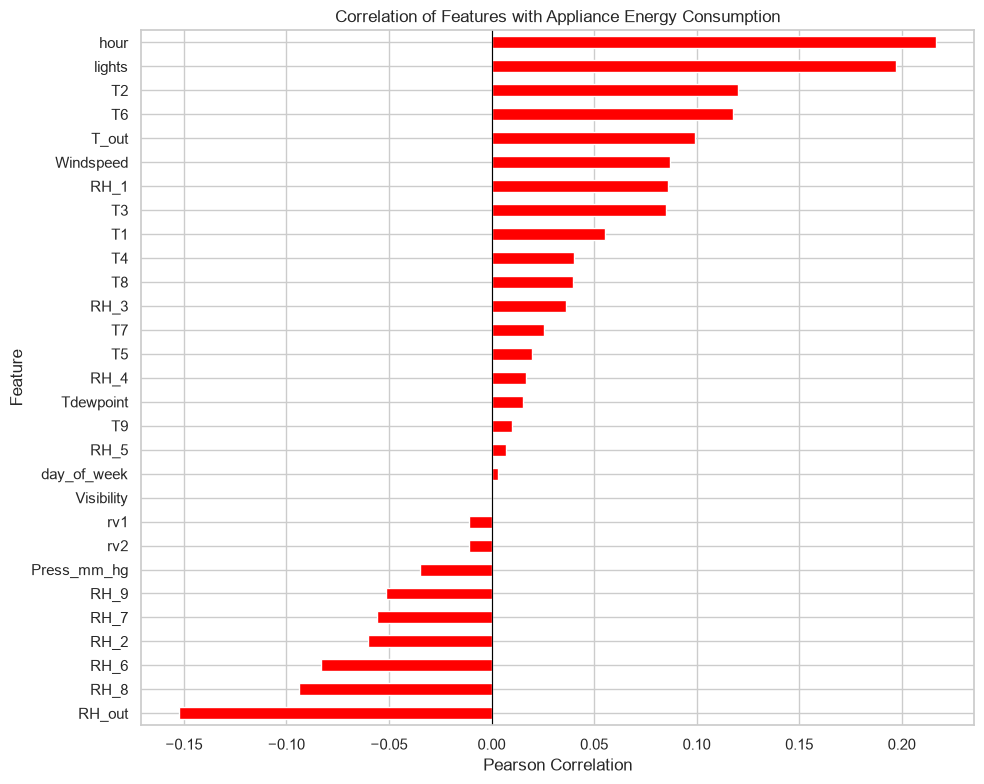

In [58]:
#Correlation with the Target Variable


#select numeric columns for correlation analysis
numeric_df = df.select_dtypes(include=np.number)

#calculate correlations between numeric variables
correlation_matrix = numeric_df.corr()

#extract each feature's correlation with Appliances
target_correlation = (correlation_matrix["Appliances"].drop("Appliances").sort_values(key=lambda values: values.abs(), ascending=False))

#display correlations ranked by absolute strength
print("Feature correlations with Appliances:")
display(target_correlation.to_frame(name="Correlation with Appliances"))

#plot the correlation strengths as a bar chart
plt.figure(figsize=(10, 8))

target_correlation.sort_values().plot(kind="barh",color="red")

plt.title("Correlation of Features with Appliance Energy Consumption")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()


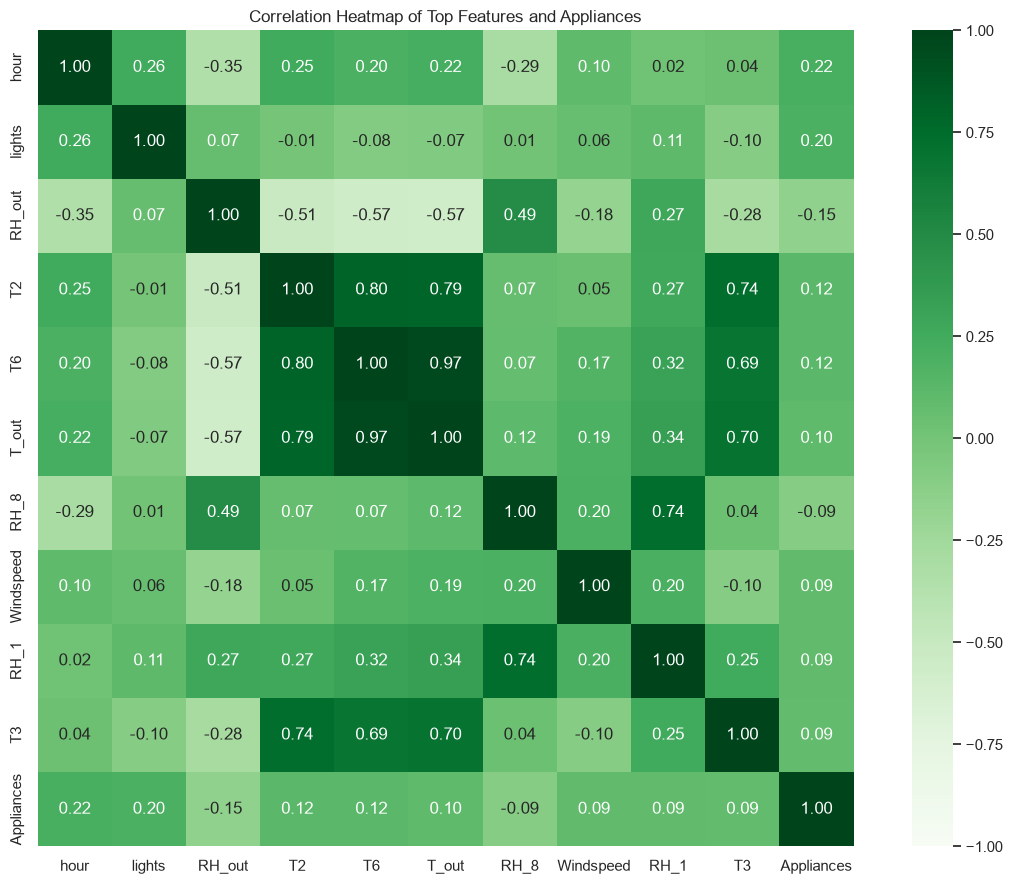

In [59]:
#Correlation Heatmap


#select the 10 features with the strongest absolute
#correlation with Appliances
top_features = target_correlation.abs().nlargest(10).index.tolist()

#include Appliances itself in the heatmap
selected_features = top_features + ["Appliances"]

#calculate correlations for the selected variables
selected_correlation = numeric_df[selected_features].corr()

#plot the correlation heatmap
plt.figure (figsize=(12, 9))

sns.heatmap (selected_correlation,annot=True,fmt=".2f",cmap="Greens",center=0,vmin=-1,vmax=1,square=True)

plt.title ("Correlation Heatmap of Top Features and Appliances")

plt.tight_layout()
plt.show()


In [60]:

#EDA SUMMARY



print("__ EXPLORATORY DATA ANALYSIS SUMMARY __ \n")

print(f"Total records: {len(df):,}")
print(f"Total columns: {df.shape[1]:,}")

print (f"Time period: {df['date'].min()} to {df['date'].max()}")

print (f"Total missing values: {df.isnull().sum().sum():,}")

print (f"Duplicate rows: {df.duplicated().sum():,}")

print (f"Minimum appliance consumption: {df['Appliances'].min():.2f} Wh")

print (f"Maximum appliance consumption: {df['Appliances'].max():.2f} Wh")

print (f"Mean appliance consumption: {df['Appliances'].mean():.2f} Wh")

print (f"Median appliance consumption: {df['Appliances'].median():.2f} Wh")

print (f"Standard deviation: {df['Appliances'].std():.2f} Wh")

print (f"Target skewness: {df['Appliances'].skew():.2f}")

print("\nTop 5 features correlated with Appliances:")
display(target_correlation.head(5).to_frame("Correlation"))


__ EXPLORATORY DATA ANALYSIS SUMMARY __ 

Total records: 19,735
Total columns: 32
Time period: 2016-01-11 17:00:00 to 2016-05-27 18:00:00
Total missing values: 0
Duplicate rows: 0
Minimum appliance consumption: 10.00 Wh
Maximum appliance consumption: 1080.00 Wh
Mean appliance consumption: 97.69 Wh
Median appliance consumption: 60.00 Wh
Standard deviation: 102.52 Wh
Target skewness: 3.39

Top 5 features correlated with Appliances:


,Correlation
hour,0.216792
lights,0.197278
RH_out,-0.152282
T2,0.120073
T6,0.117638


## 2. Handling Missing Value

In [61]:

#count missing values in each column
missing_values = df.isnull().sum()

#display the missing value count for every column
print("Missing values in each column :")
display(missing_values.to_frame(name="Missing Count"))

#calculate the total number of missing values
total_missing = df.isnull().sum().sum()
print("\nTotal missing values :", total_missing)

#calculate the percentage of missing values in each column
missing_percentage = (df.isnull().mean() * 100).round(2)

print("\nMissing-value percentage :")
display(missing_percentage.to_frame(name="Missing Percentage (%)"))


Missing values in each column :


,Missing Count
date,0
Appliances,0
lights,0
T1,0
RH_1,0
T2,0
RH_2,0
T3,0
RH_3,0
T4,0



Total missing values : 0

Missing-value percentage :


,Missing Percentage (%)
date,0.0
Appliances,0.0
lights,0.0
T1,0.0
RH_1,0.0
T2,0.0
RH_2,0.0
T3,0.0
RH_3,0.0
T4,0.0



### Missing Value Analysis Justification

- The dataset was checked for missing values across all columns.
- No missing values were detected in any column.
- Therefore no missing value imputation or row removal was required.
- The original observations were retained for the next stages of preprocessing.



## 3. Outlier Detection and Treatment


In [62]:
#Using the IQR Method

#select the target column
appliances = df["Appliances"]

#calculate the first and third quartiles
Q1 = appliances.quantile(0.25)
Q3 = appliances.quantile(0.75)
#calculate the Interquartile Range
IQR = Q3 - Q1

#calculate the lower and upper limits
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

#identify potential outliers
outliers = df[
    (df["Appliances"] < lower_bound) |
    (df["Appliances"] > upper_bound)
]

#display the results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("\nTotal records:", len(df))
print("Potential outliers:", len(outliers))
print("Outlier percentage:", round(len(outliers) / len(df) * 100, 2), "%")

#inspect some potential outlier records
display(outliers[["date", "Appliances"]].head(10))

Q1: 50.0
Q3: 100.0
IQR: 50.0
Lower bound: -25.0
Upper bound: 175.0

Total records: 19735
Potential outliers: 2138
Outlier percentage: 10.83 %


,date,Appliances
10,2016-01-11 18:40:00,230
11,2016-01-11 18:50:00,580
12,2016-01-11 19:00:00,430
13,2016-01-11 19:10:00,250
21,2016-01-11 20:30:00,190
31,2016-01-11 22:10:00,400
32,2016-01-11 22:20:00,400
33,2016-01-11 22:30:00,390
34,2016-01-11 22:40:00,240
46,2016-01-12 00:40:00,310


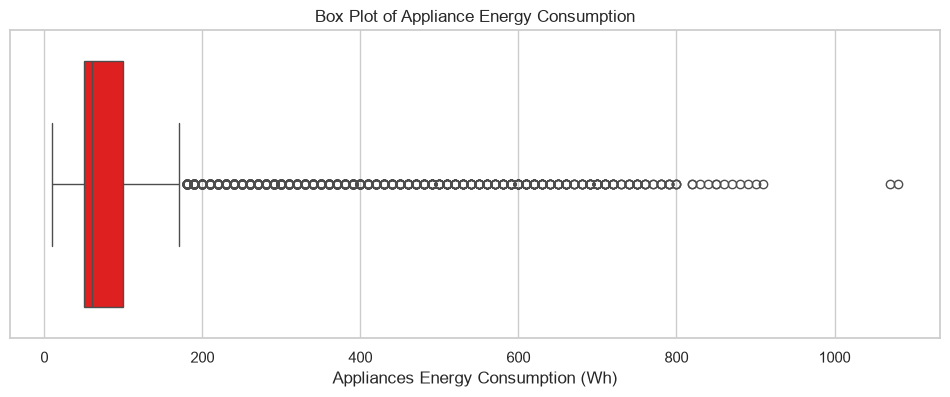

In [63]:
#create a box plot to visualize potential outliers

plt.figure(figsize=(12, 4))

sns.boxplot(x=df["Appliances"], color="red")

plt.title("Box Plot of Appliance Energy Consumption")
plt.xlabel("Appliances Energy Consumption (Wh)")

plt.show()

In [64]:
#inspect the distribution of potential outliers

print("Lowest potential outliers:")
display(
    outliers[["date", "Appliances"]]
    .sort_values("Appliances")
    .head(10)
)

print ("Highest potential outliers:")
display (outliers[["date", "Appliances"]].sort_values("Appliances", ascending=False).head(10))

#check the range of the flagged readings
print("Minimum outlier value:", outliers["Appliances"].min())
print("Maximum outlier value:", outliers["Appliances"].max())

Lowest potential outliers:


,date,Appliances
5905,2016-02-21 17:10:00,180
19439,2016-05-25 16:50:00,180
1839,2016-01-24 11:30:00,180
1838,2016-01-24 11:20:00,180
1833,2016-01-24 10:30:00,180
5624,2016-02-19 18:20:00,180
3041,2016-02-01 19:50:00,180
13799,2016-04-16 12:50:00,180
8364,2016-03-09 19:00:00,180
19526,2016-05-26 07:20:00,180


Highest potential outliers:


,date,Appliances
731,2016-01-16 18:50:00,1080
1451,2016-01-21 18:50:00,1070
432,2016-01-14 17:00:00,910
12088,2016-04-04 15:40:00,900
1452,2016-01-21 19:00:00,890
10668,2016-03-25 19:00:00,880
14693,2016-04-22 17:50:00,870
9031,2016-03-14 10:10:00,860
19582,2016-05-26 16:40:00,850
1821,2016-01-24 08:30:00,850


Minimum outlier value: 180
Maximum outlier value: 1080


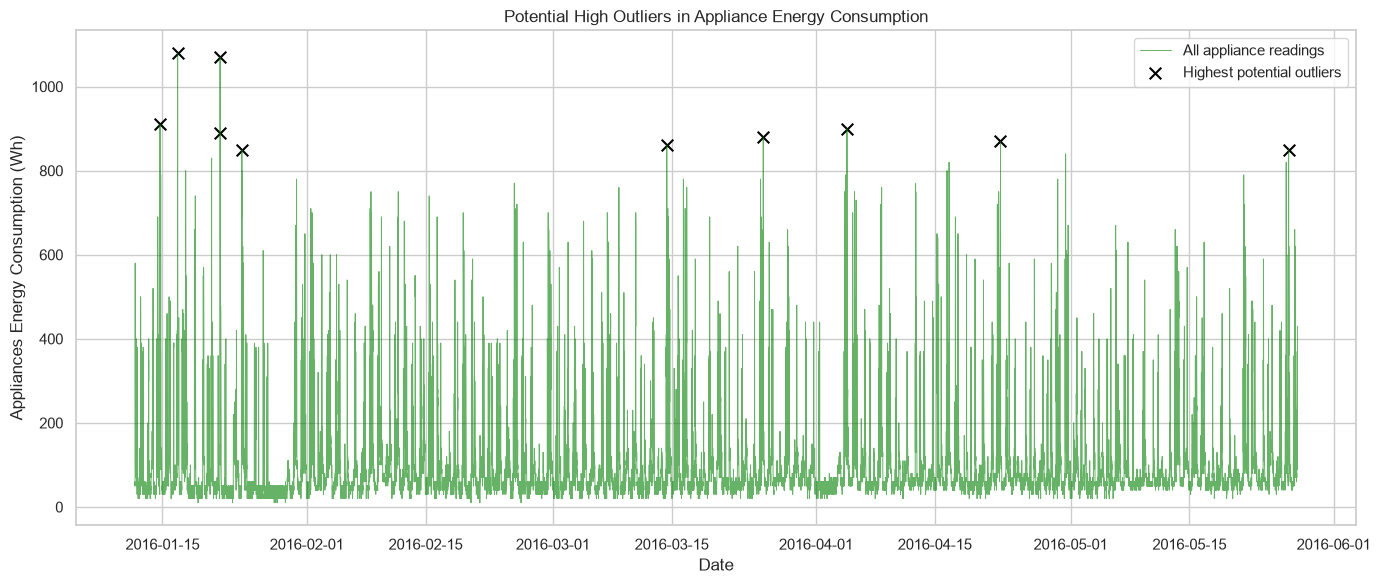

In [74]:
#Inspect Outliers Over Time

#select the 10 highest appliance readings
highest_outliers = outliers.nlargest(10, "Appliances")

#plot the original energy readings around each selected outlier
plt.figure(figsize=(14, 6))

plt.plot (df["date"],df["Appliances"],label="All appliance readings",alpha=0.6,linewidth=0.7,color = "green")

plt.scatter(highest_outliers["date"],highest_outliers["Appliances"],label="Highest potential outliers",color = "black",marker="x",s=70)

plt.title("Potential High Outliers in Appliance Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Appliances Energy Consumption (Wh)")
plt.legend()
plt.tight_layout()
plt.show()

,date,Appliances
725,2016-01-16 17:50:00,420
726,2016-01-16 18:00:00,280
727,2016-01-16 18:10:00,300
728,2016-01-16 18:20:00,350
729,2016-01-16 18:30:00,270
730,2016-01-16 18:40:00,560
731,2016-01-16 18:50:00,1080
732,2016-01-16 19:00:00,750
733,2016-01-16 19:10:00,390
734,2016-01-16 19:20:00,350


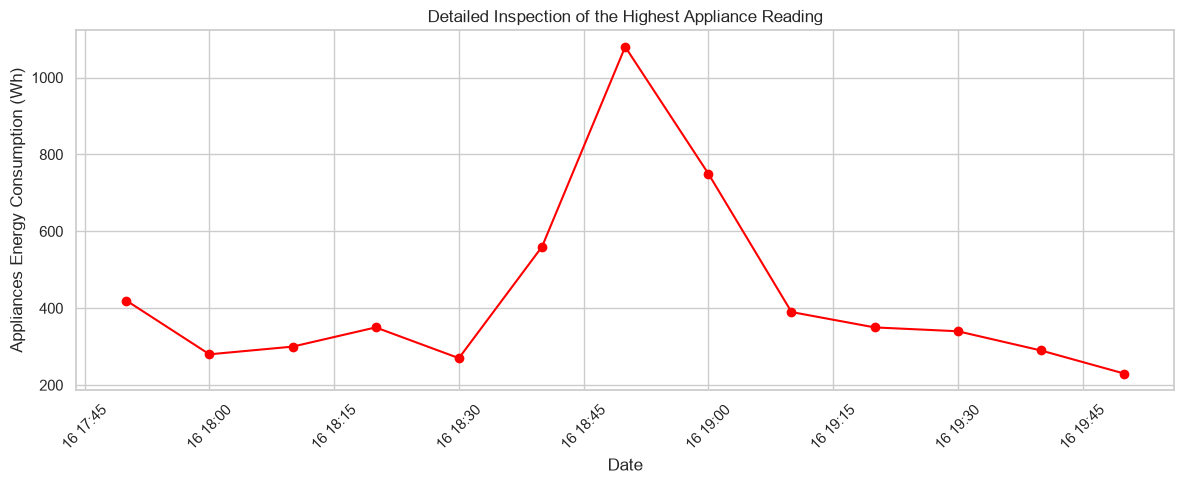

In [66]:
#Inspect the time period around the highest appliance reading

#find the row containing the maximum reading
max_index = df["Appliances"].idxmax()

#select 6 observations before and after the maximum
start_index = max(0, max_index - 6)
end_index = min(len(df), max_index + 7)

#display the readings in chronological order
display (df.loc[start_index:end_index - 1, ["date", "Appliances"]])

#plot the local time period
local_data = df.loc[start_index:end_index - 1]

plt.figure(figsize=(12, 5))
plt.plot(local_data["date"],local_data["Appliances"],color = "red",marker="o")

plt.title("Detailed Inspection of the Highest Appliance Reading")
plt.xlabel("Date")
plt.ylabel("Appliances Energy Consumption (Wh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4. Outlier Detection and Treatment

The Interquartile Range (IQR) method was used to identify potential outliers in the `Appliances` target variable. Out of 19,735 observations, 2,138 readings (10.83%) were flagged as potential outliers.

Box plots and time-series visualizations were used to inspect the unusual readings. The flagged values ranged from 180 Wh to 1080 Wh. A detailed inspection of the highest reading showed a sharp increase followed by a decrease in consumption. However, the available data did not establish that this reading was erroneous.

Therefore, all original observations were retained, and no outliers were removed or imputed at this stage. This decision preserves potentially genuine energy-consumption patterns and maintains the chronological structure required for time-series forecasting. Further treatment may be considered if additional evidence of data errors or model-performance issues is found.

## 4. Data Scaling and Normalization
##### Im going to split the dataset before scaling for protect from data leakage

## Data Split chronologically

In [67]:
#Chronological Train TestsSplit

#sort observations from earliest to latest
df = df.sort_values("date").reset_index(drop=True)

#calculate the 80% split point
split_index = int(len(df) * 0.80)

#first 80% for training
train_df = df.iloc[:split_index].copy()

#final 20% for testing
test_df = df.iloc[split_index:].copy()

#display the results
print("Total records:", len(df))
print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("\nTraining period:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting period:")
print(test_df["date"].min(), "to", test_df["date"].max())

Total records: 19735
Training records: 15788
Testing records: 3947

Training period:
2016-01-11 17:00:00 to 2016-04-30 08:10:00

Testing period:
2016-04-30 08:20:00 to 2016-05-27 18:00:00


In [68]:
#Feature Scaling (standardization)

#select numeric input features
#exclude the target and duplicate rv2 feature
feature_columns = [col for col in train_df.select_dtypes(include=np.number).columns
    if col not in ["Appliances", "rv2"]]

#separate input features and prediction target
X_train = train_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

y_train = train_df[["Appliances"]].copy()
y_test = test_df[["Appliances"]].copy()

#create separate scalers for features and target
X_scaler = StandardScaler()
y_scaler = StandardScaler()

#fit on training data only
X_train_scaled = X_scaler.fit_transform(X_train)
y_train_scaled = y_scaler.fit_transform(y_train)

#transform test data using the existing scalers
X_test_scaled = X_scaler.transform(X_test)
y_test_scaled = y_scaler.transform(y_test)

#verify the results
print("Training input:", X_train_scaled.shape)
print("Testing input:", X_test_scaled.shape)
print("Training target:", y_train_scaled.shape)
print("Testing target:", y_test_scaled.shape)

print("\nScaling completed successfully.")

Training input: (15788, 28)
Testing input: (3947, 28)
Training target: (15788, 1)
Testing target: (3947, 1)

Scaling completed successfully.


In [69]:
# Verify chronological split and scaling

print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("\nTraining ends:", train_df["date"].max())
print("Testing starts:", test_df["date"].min())

print("\nScaled training features:", X_train_scaled.shape)
print("Scaled testing features:", X_test_scaled.shape)

print("\nMissing values in training features:", np.isnan(X_train_scaled).sum())
print("Missing values in testing features:", np.isnan(X_test_scaled).sum())

Training records: 15788
Testing records: 3947

Training ends: 2016-04-30 08:10:00
Testing starts: 2016-04-30 08:20:00

Scaled training features: (15788, 28)
Scaled testing features: (3947, 28)

Missing values in training features: 0
Missing values in testing features: 0


In [70]:

#project folders: this notebook is inside notebooks/
from pathlib import Path
project_root = Path("..")

raw_path = project_root / "data" / "raw" / "energy_data_set.csv"
processed_path = project_root / "data" / "processed"
processed_path.mkdir(parents=True, exist_ok=True)

#reload the original dataset for a clean EDA output
eda_df = pd.read_csv(raw_path, parse_dates=["date"])

#sort records chronologically
eda_df = eda_df.sort_values("date").reset_index(drop=True)

#save the dataset for the Feature Engineering notebook
eda_output_path = processed_path / "energy_data_eda.csv"
eda_df.to_csv(eda_output_path, index=False)

print("Saved EDA dataset to:", eda_output_path)
print("Dataset shape:", eda_df.shape)


Saved EDA dataset to: ../data/processed/energy_data_eda.csv
Dataset shape: (19735, 29)
